# K-Means on Penguin Data: Do Clusters Match Species?

The `penguins` dataset has measurements for three species: **Adelie**, **Chinstrap**, and **Gentoo**. Since we already know there are three species, we'll cluster with `k = 3` and then check how well the unsupervised clusters line up with the real species labels. K-Means never sees the `species` column while clustering - we only use it afterward to grade how well the clusters did.

# Import the libraries and dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

%matplotlib inline

In [2]:
df = pd.read_csv('data/penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


A few rows have missing measurements (`NaN`), which K-Means can't handle, so we drop them. There aren't many, so this is safe here.

In [3]:
print('Rows before dropping missing values:', len(df))
df = df.dropna().reset_index(drop=True)
print('Rows after dropping missing values: ', len(df))
df['species'].value_counts()

Rows before dropping missing values: 344
Rows after dropping missing values:  333


species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

# Prepare the features

We'll cluster on the four numeric body measurements: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`. These are on very different scales - `body_mass_g` is in the thousands while `bill_depth_mm` is under 25. K-Means uses straight-line distance, so without scaling, `body_mass_g` would completely dominate the distance calculation and the other three measurements would barely matter. `StandardScaler` rescales every feature to have a mean of 0 and a standard deviation of 1, so each measurement gets an equal say.

In [4]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[-0.89604189,  0.7807321 , -1.42675157, -0.56847478],
       [-0.82278787,  0.11958397, -1.06947358, -0.50628618],
       [-0.67627982,  0.42472926, -0.42637319, -1.1903608 ],
       [-1.33556603,  1.0858774 , -0.56928439, -0.94160639],
       [-0.85941488,  1.74702554, -0.78365118, -0.69285199]])

# Algorithm: fit K-Means with k = 3

In [5]:
model = KMeans(n_clusters=3, n_init='auto', random_state=42)
clusters = model.fit_predict(X_scaled)

# Centroids are in scaled units; convert back to the original measurement units
# (mm and grams) so they're easier to read.
centroids = scaler.inverse_transform(model.cluster_centers_)
pd.DataFrame(centroids, columns=features)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,38.276744,18.121705,188.627907,3593.798450
1,47.568067,14.996639,217.235294,5092.436975
2,47.662353,18.748235,196.917647,3898.235294


# Compare clusters to species

K-Means labels its clusters `0`, `1`, `2` with no idea which number means which species - the numbers are arbitrary. To see how well clustering recovered the species groups, we cross-tabulate the real `species` column against the cluster number each penguin landed in.

In [6]:
comparison = pd.crosstab(df['species'], clusters, rownames=['species'], colnames=['cluster'])
comparison

cluster,0,1,2
species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


Each row is a species, each column is a cluster number, and each cell is how many penguins of that species ended up in that cluster. If clustering matched species perfectly, each row would have one big number and zeros everywhere else.

Two simple scores summarize the table above:
- **Purity**: for each cluster, take its most common species and count those penguins as "correct"; purity is the fraction of all penguins that are correct this way. It always improves with more clusters, so it's best used (like here) when you already expect a specific number of groups.
- **Adjusted Rand Index (ARI)**: compares the clustering to the species labels more rigorously, correcting for chance agreement. It's 1.0 for a perfect match, 0.0 for what you'd expect from random guessing, and can go negative for worse-than-chance groupings.

In [7]:
purity = comparison.max(axis=0).sum() / len(df)
ari = adjusted_rand_score(df['species'], clusters)

print(f'Purity: {purity:.1%}')
print(f'Adjusted Rand Index: {ari:.3f}')

Purity: 91.9%
Adjusted Rand Index: 0.799


# Visualize clusters vs. species

Four measurements can't be plotted at once, so we'll plot `bill_length_mm` against `flipper_length_mm` - a pair that tends to separate the three species well. The left plot colors each point by the K-Means cluster it was assigned to (with the centroids as black X's); the right plot colors the same points by their true species. Similar coloring patterns on both sides means the clusters are a good match for the species.

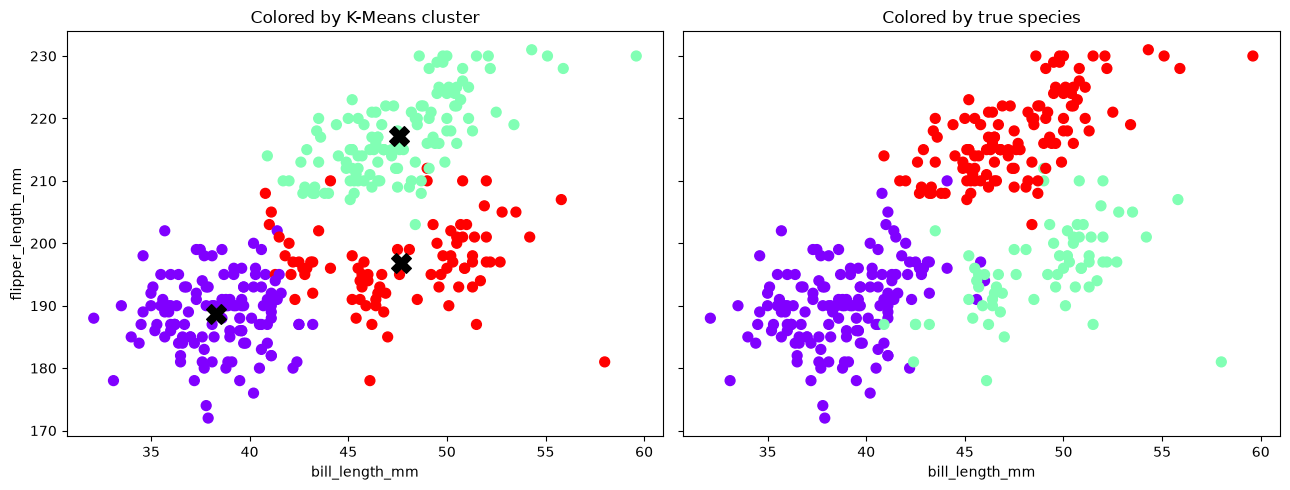

In [8]:
x_feature, y_feature = 'bill_length_mm', 'flipper_length_mm'
x_idx, y_idx = features.index(x_feature), features.index(y_feature)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

ax1.scatter(df[x_feature], df[y_feature], c=clusters, cmap='rainbow', s=50)
ax1.scatter(centroids[:, x_idx], centroids[:, y_idx], c='black', marker='X', s=200)
ax1.set_title('Colored by K-Means cluster')
ax1.set_xlabel(x_feature)
ax1.set_ylabel(y_feature)

species_codes = df['species'].astype('category').cat.codes
ax2.scatter(df[x_feature], df[y_feature], c=species_codes, cmap='rainbow', s=50)
ax2.set_title('Colored by true species')
ax2.set_xlabel(x_feature)

plt.tight_layout()
plt.show()

Run the cells above and compare the two plots - Gentoo penguins (the largest, with notably longer flippers) form a cluster K-Means separates out almost perfectly, while Adelie and Chinstrap overlap more on these two measurements and are more often confused with each other. That matches the crosstab: clustering recovers the species groups well overall (around 92% purity, ARI ~0.8 with all four features), but it isn't a perfect 1-to-1 match, which is typical for K-Means - it finds *round, evenly sized* groups based on distance, not necessarily whatever categories a human would draw.